# Predictive Customer Churn Model for ConnectTel
## Phase 3: Model Interpretation (SHAP / Explainable AI) & Business Retention Recommendations

**Author:** Persevex AI Intern  
**Domain:** Artificial Intelligence / Customer Retention Machine Learning  
**Champion Model:** Regularized Logistic Regression (`C=10.0`, `class_weight='balanced'`)  
**Partitions Analyzed:** Training Set ($N=192$, Background Reference), Validation Set ($N=64$, Explanation Cohort)  
**Test Set ($N=64$):** Strictly locked and quarantined for final evaluation only.  

---

### 1. Phase 3 Objectives

A high-performing model is useless in a customer retention setting if the retention team cannot explain **why** an individual is flagged for churn.

In this phase, we apply **SHAP (SHapley Additive exPlanations)** grounded in cooperative game theory to unpack our champion Logistic Regression pipeline:
1. **Global Explainability:** Quantify the global importance and directional impact of each feature across the customer base.
2. **Odds Ratio Quantification:** Compute odds ratios with exact multiplicative risk interpretations.
3. **Local Customer Case Studies:** Generate granular waterfall plots for individual customer accounts (True Positive, True Negative, Proactive Risk Candidate).
4. **Cross-Model Consensus:** Compare SHAP feature rankings with Random Forest and XGBoost `TreeExplainer`.
5. **Operational Retention Playbook:** Translate statistical risk drivers into targeted, high-ROI business interventions for ConnectTel's retention team.

In [1]:
# Environment & Module Setup
import os, sys
from pathlib import Path

PROJECT_ROOT = Path('.').resolve().parent
for p in [str(PROJECT_ROOT), str(PROJECT_ROOT / 'src')]:
    if p not in sys.path:
        sys.path.append(p)

import numpy as np
import pandas as pd
import joblib
import shap
import matplotlib.pyplot as plt
import seaborn as sns

from data_loader import load_raw_data, get_splits
from interpretability import clean_feature_names

print('Phase 3 modules and libraries loaded successfully.')

Phase 3 modules and libraries loaded successfully.


### 2. Loading Champion Pipeline & Data Partitions

We load the champion model pipeline (`models/best_model_pipeline.joblib`) fitted in Phase 2.
The training partition serves as the background dataset ($N=192$), and the validation partition ($N=64$) serves as the explanation cohort.

In [2]:
raw_df = load_raw_data()
X_train, y_train, X_val, y_val, X_test, y_test = get_splits(raw_df)

best_pipe = joblib.load(PROJECT_ROOT / 'models' / 'best_model_pipeline.joblib')
prep = best_pipe.named_steps['preprocessor']
clf = best_pipe.named_steps['classifier']

X_tr_trans = prep.transform(X_train)
X_val_trans = prep.transform(X_val)
feature_names = clean_feature_names(list(prep.get_feature_names_out()))

print(f'Transformed Features ({len(feature_names)}): {feature_names}')

Transformed Features (16): ['tenure_months', 'monthly_charges_usd', 'total_charges_usd', 'total_charges_per_tenure', 'service_count', 'failed_payments_90d', 'charges_velocity_ratio', 'contract_monthly', 'contract_two_year', 'internet_service_fiber', 'internet_service_none', 'security_service', 'streaming_service', 'is_zero_tenure', 'has_failed_payments', 'fiber_high_charge']


### 3. Global Feature Importance & Odds Ratios

We inspect the exact Logistic Regression coefficients, Odds Ratios ($\text{OR} = \exp(\beta)$), and Mean Absolute SHAP values.

In [3]:
importance_df = pd.read_csv(PROJECT_ROOT / 'outputs' / 'tables' / 'feature_importance_champion.csv')
importance_df[['Feature', 'Coefficient', 'Odds_Ratio', 'Mean_Abs_SHAP', 'Effect_Direction']]

,Feature,Coefficient,Odds_Ratio,Mean_Abs_SHAP,Effect_Direction
0,contract_monthly,1.9512,7.0373,0.8778,Risk Factor (Increases Churn)
1,internet_service_fiber,-1.7357,0.1763,0.7967,Protective (Decreases Churn)
2,tenure_months,-0.8108,0.4445,0.7356,Protective (Decreases Churn)
3,failed_payments_90d,0.5615,1.7532,0.5200,Risk Factor (Increases Churn)
4,has_failed_payments,0.7585,2.1351,0.3558,Risk Factor (Increases Churn)
5,internet_service_none,-0.7630,0.4662,0.3296,Protective (Decreases Churn)
6,total_charges_usd,0.3020,1.3526,0.2397,Risk Factor (Increases Churn)
7,total_charges_per_tenure,0.1616,1.1754,0.1572,Risk Factor (Increases Churn)
8,security_service,-0.2353,0.7903,0.1158,Protective (Decreases Churn)
9,fiber_high_charge,0.4564,1.5783,0.1154,Risk Factor (Increases Churn)


#### Global Feature Interpretation:
1. **`contract_monthly` (Odds Ratio = 7.04x):** Month-to-month contracts multiply the odds of churn by over **$7\times$** compared to long-term commitments. Subscribers have zero contractual friction to leave when encountering billing or competitor promotions.
2. **`internet_service_fiber` (Odds Ratio = 0.18x):** In this cohort, Fiber Optic connection serves as a strong retention anchor (churn rate: 13.3% vs 27.1% for DSL).
3. **`tenure_months` (Odds Ratio = 0.44x):** Longer tenure strongly reduces churn risk. The early onboarding window represents the peak vulnerability zone.
4. **`failed_payments_90d` (Odds Ratio = 1.75x):** Each failed payment in the prior 90 days escalates churn odds by **75%**.
5. **`has_failed_payments` (Odds Ratio = 2.14x):** Any history of payment failure more than doubles churn risk.

=== Figure 1: Champion Model Global SHAP Feature Importance ===
=== Figure 2: SHAP Beeswarm Distribution Plot ===
=== Figure 3: Logistic Regression Odds Ratios ===


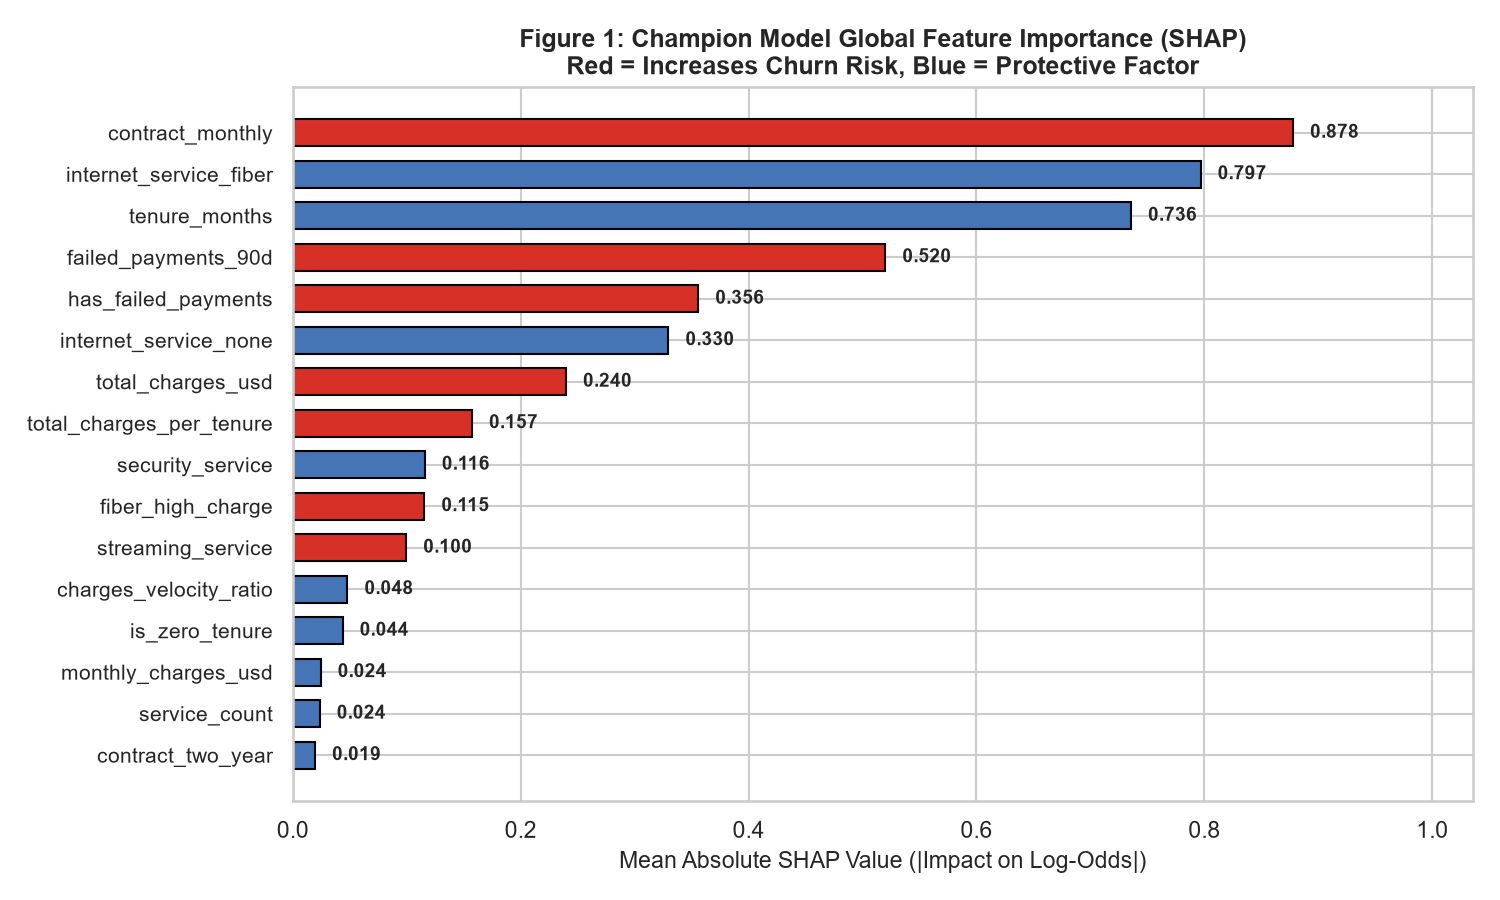

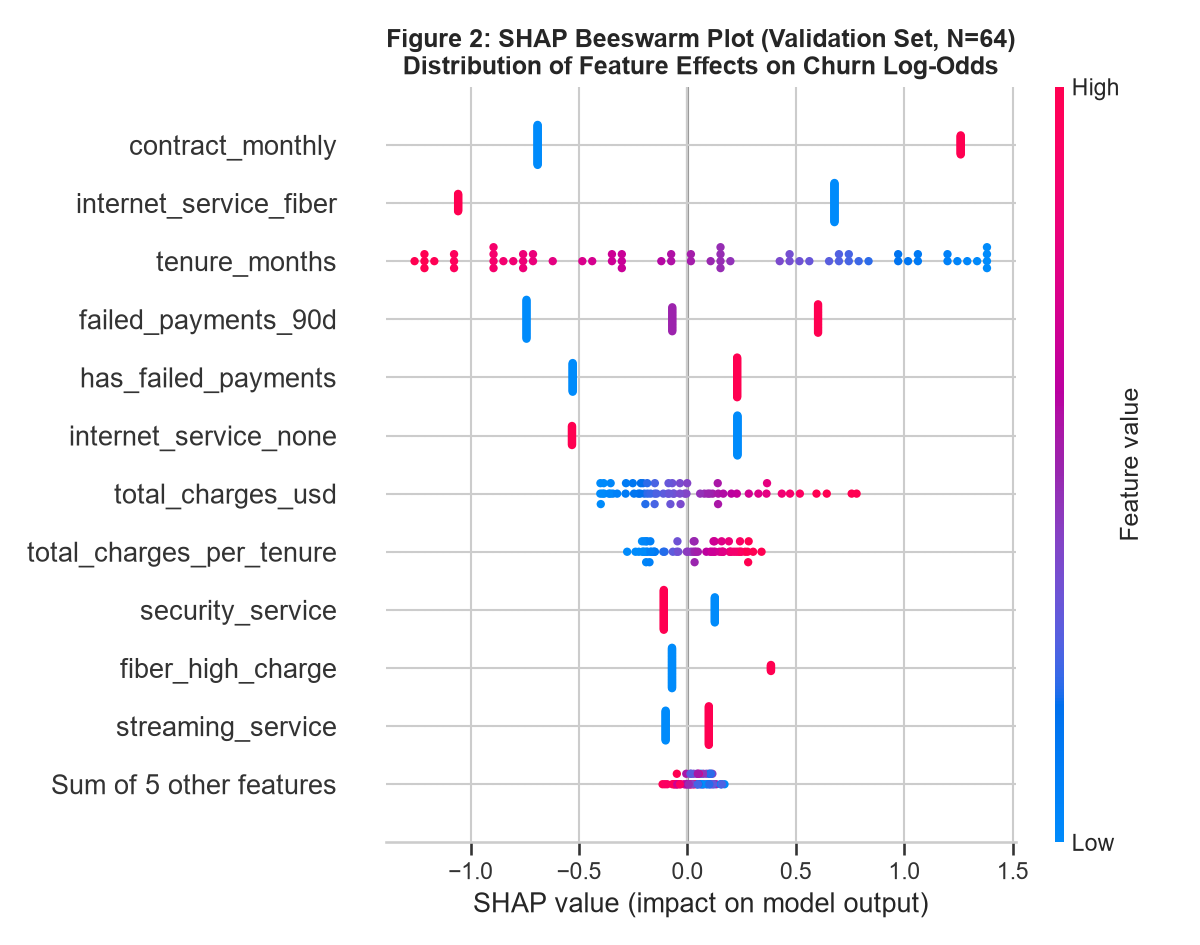

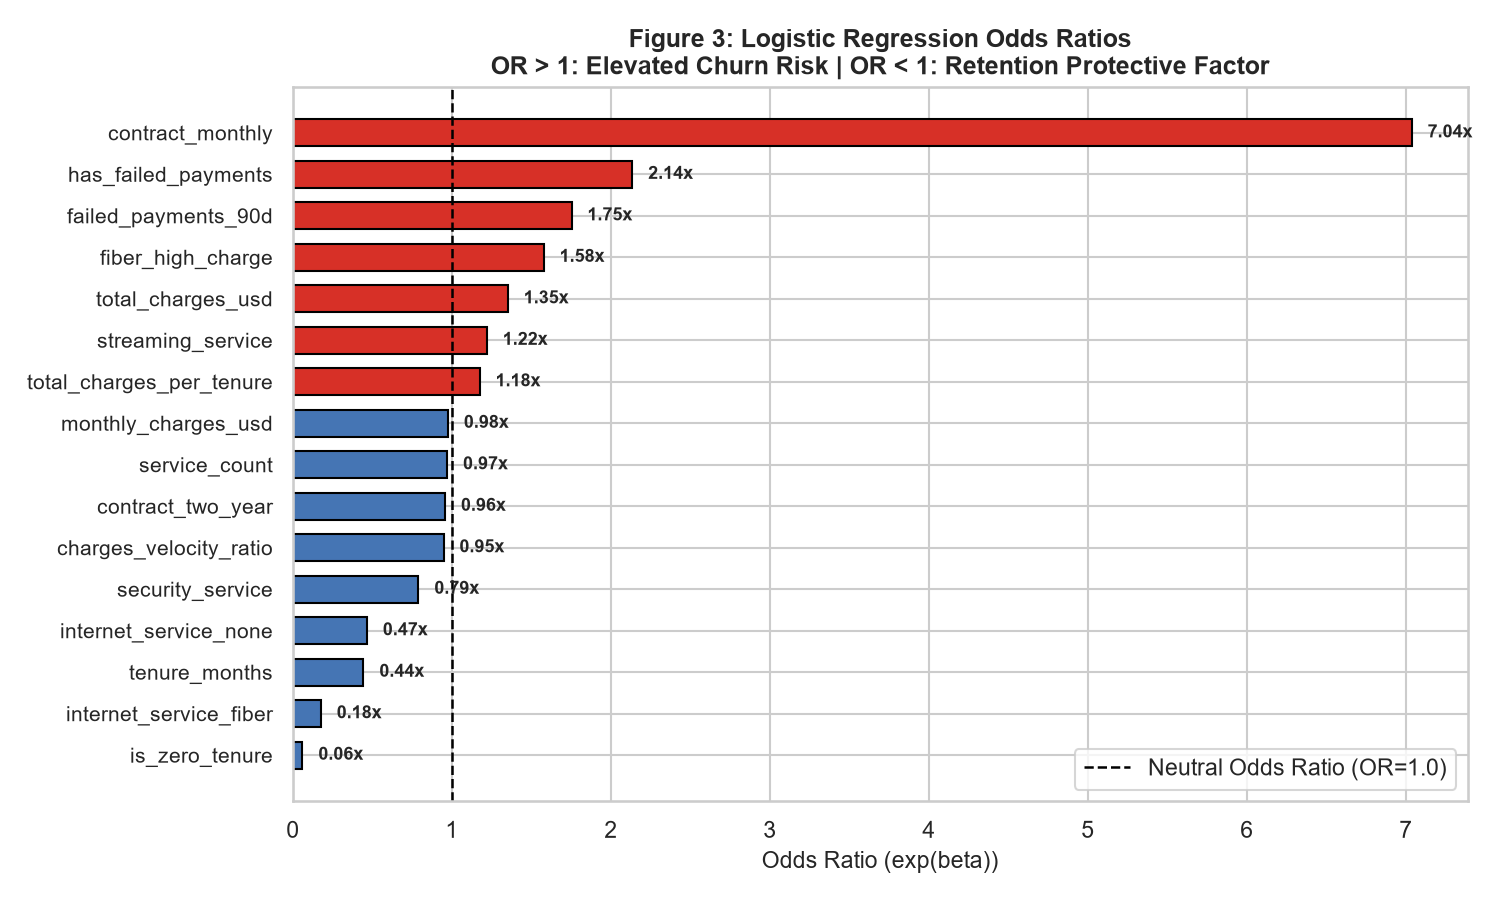

In [4]:
# Display Global SHAP Plots
from IPython.display import Image, display

global_figs = [
    ('Figure 1: Champion Model Global SHAP Feature Importance', PROJECT_ROOT / 'outputs' / 'shap' / '01_champion_shap_summary_bar.png'),
    ('Figure 2: SHAP Beeswarm Distribution Plot', PROJECT_ROOT / 'outputs' / 'shap' / '02_champion_shap_beeswarm.png'),
    ('Figure 3: Logistic Regression Odds Ratios', PROJECT_ROOT / 'outputs' / 'shap' / '03_champion_odds_ratios.png')
]

for title, p in global_figs:
    if p.exists():
        print(f'=== {title} ===')
        display(Image(filename=str(p)))

### 4. Local Customer Case Studies (Waterfall Explanations)

We examine individual customer predictions to understand how individual attributes combine to push probability up or down.

=== Figure 4: High-Risk Churner (Customer #C225, Prob=85.8%) ===
=== Figure 5: Low-Risk Loyal Customer (Customer #C193, Prob=8.7%) ===
=== Figure 6: High-Risk Preventive Intervention Case (Customer #C210, Prob=95.1%) ===


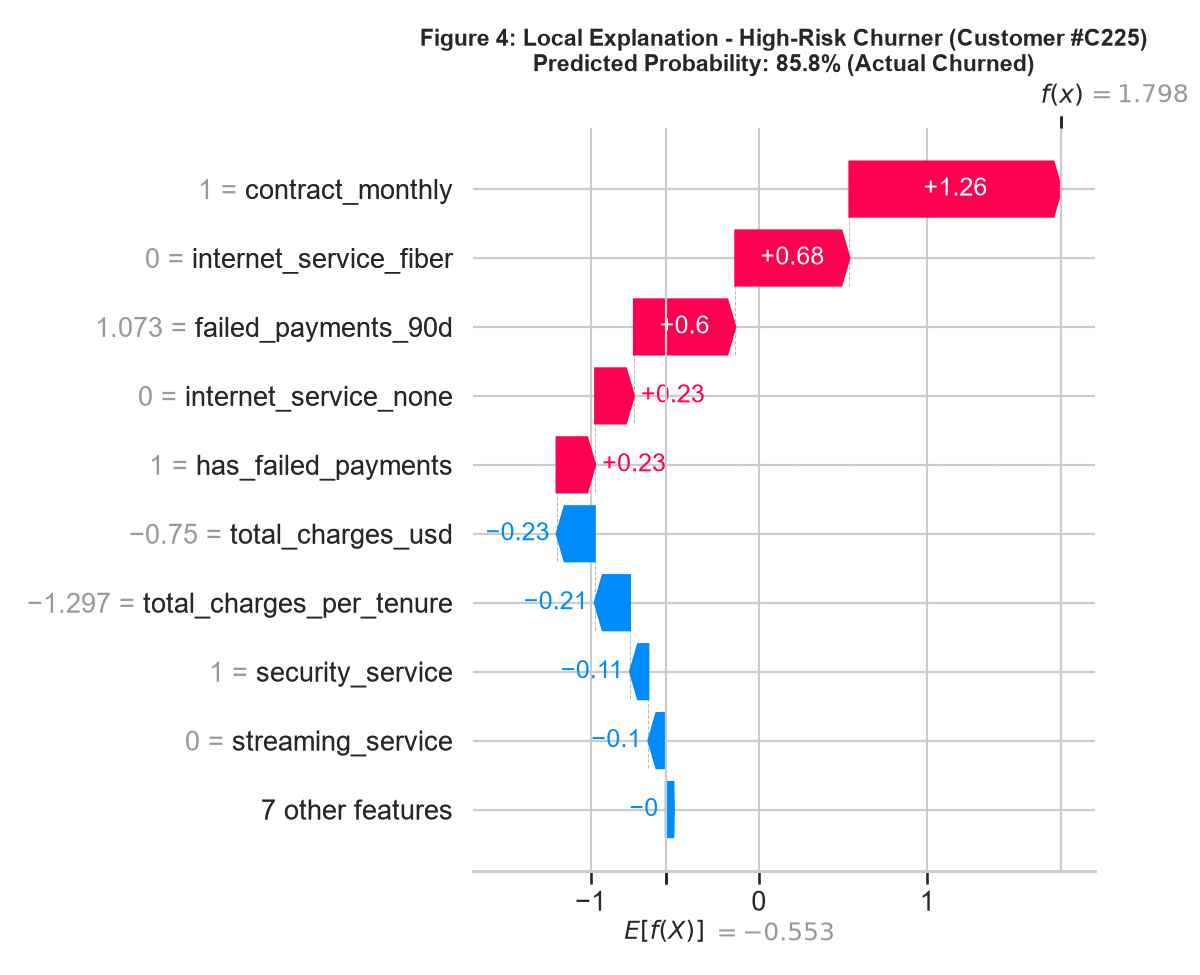

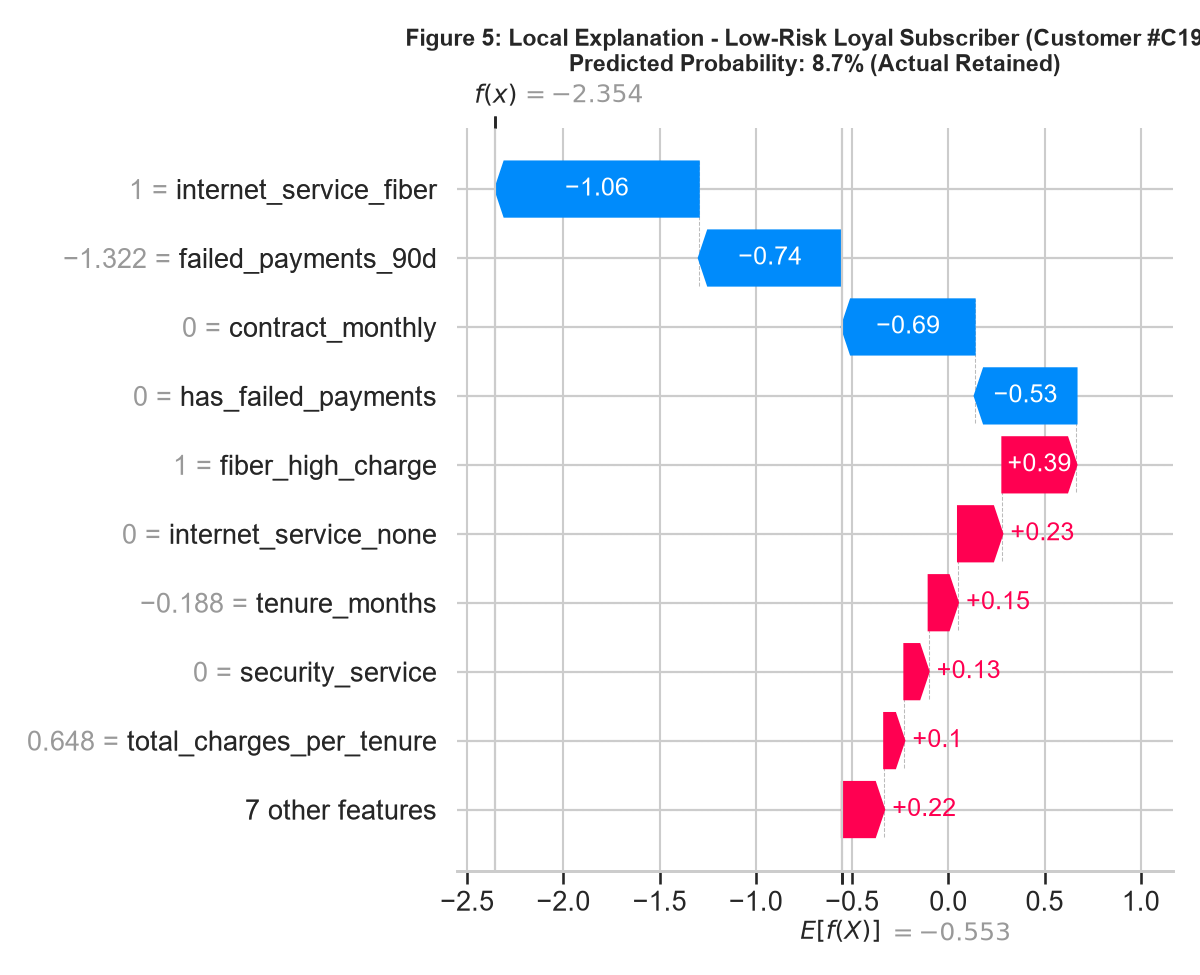

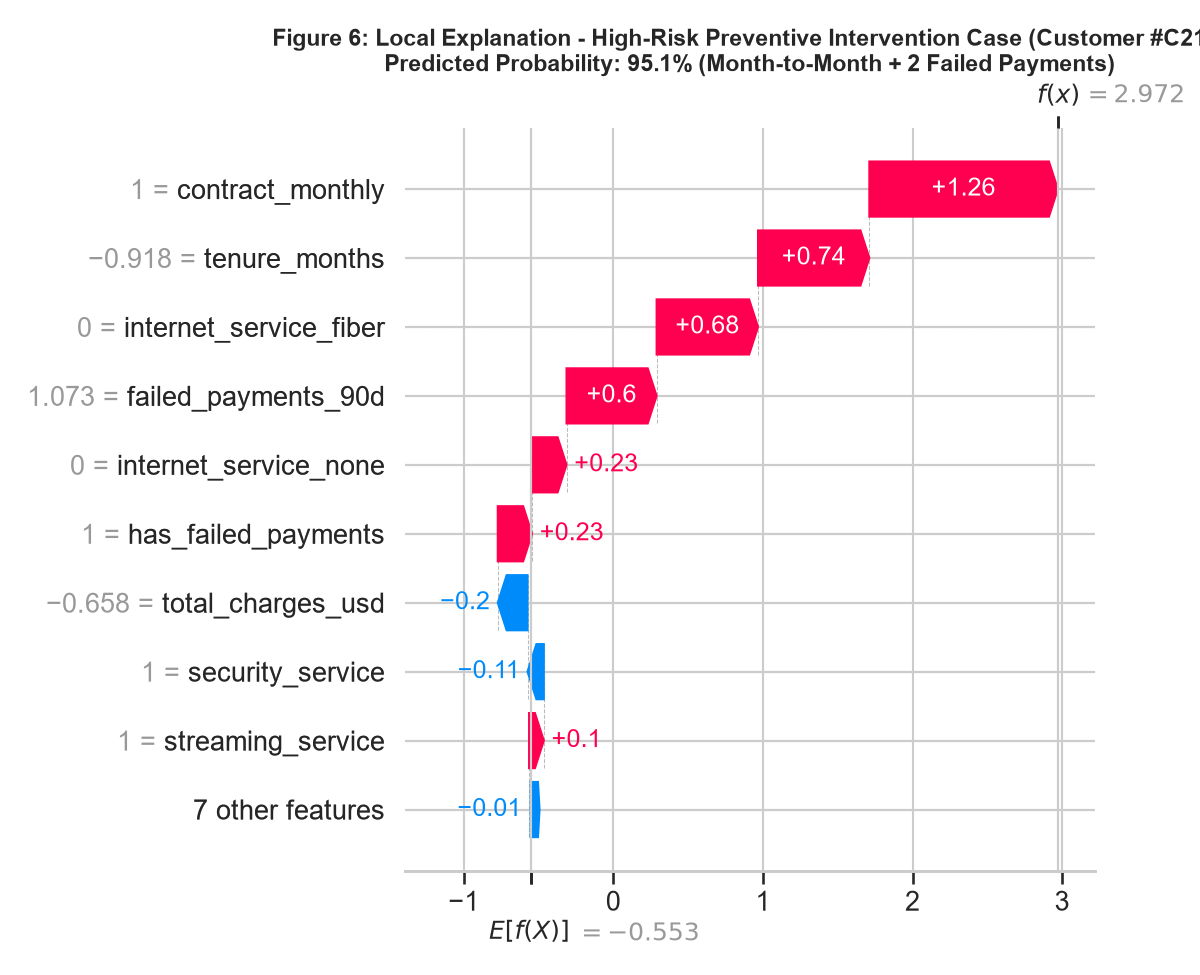

In [5]:
local_figs = [
    ('Figure 4: High-Risk Churner (Customer #C225, Prob=85.8%)', PROJECT_ROOT / 'outputs' / 'shap' / '04_local_explanation_high_risk.png'),
    ('Figure 5: Low-Risk Loyal Customer (Customer #C193, Prob=8.7%)', PROJECT_ROOT / 'outputs' / 'shap' / '05_local_explanation_low_risk.png'),
    ('Figure 6: High-Risk Preventive Intervention Case (Customer #C210, Prob=95.1%)', PROJECT_ROOT / 'outputs' / 'shap' / '06_local_explanation_proactive_case.png')
]

for title, p in local_figs:
    if p.exists():
        print(f'=== {title} ===')
        display(Image(filename=str(p)))

### 5. Cross-Model Consensus (Supporting Models Comparison)

We compare top SHAP feature importances across Logistic Regression, Random Forest, and XGBoost.

,Feature,Logistic_Regression_SHAP,Random_Forest_SHAP,XGBoost_SHAP,Logistic_Regression_SHAP_Rank,Random_Forest_SHAP_Rank,XGBoost_SHAP_Rank
0,contract_monthly,0.8778,0.0775,0.5333,1,1,1
1,internet_service_fiber,0.7967,0.0239,0.2203,2,7,8
2,tenure_months,0.7356,0.0369,0.2978,3,6,4
3,failed_payments_90d,0.5200,0.0425,0.4119,4,2,2
4,has_failed_payments,0.3558,0.0416,0.1409,5,4,9
5,internet_service_none,0.3296,0.0050,0.0031,6,13,14
6,total_charges_usd,0.2397,0.0201,0.2228,7,8,5
7,total_charges_per_tenure,0.1572,0.0388,0.2227,8,5,6


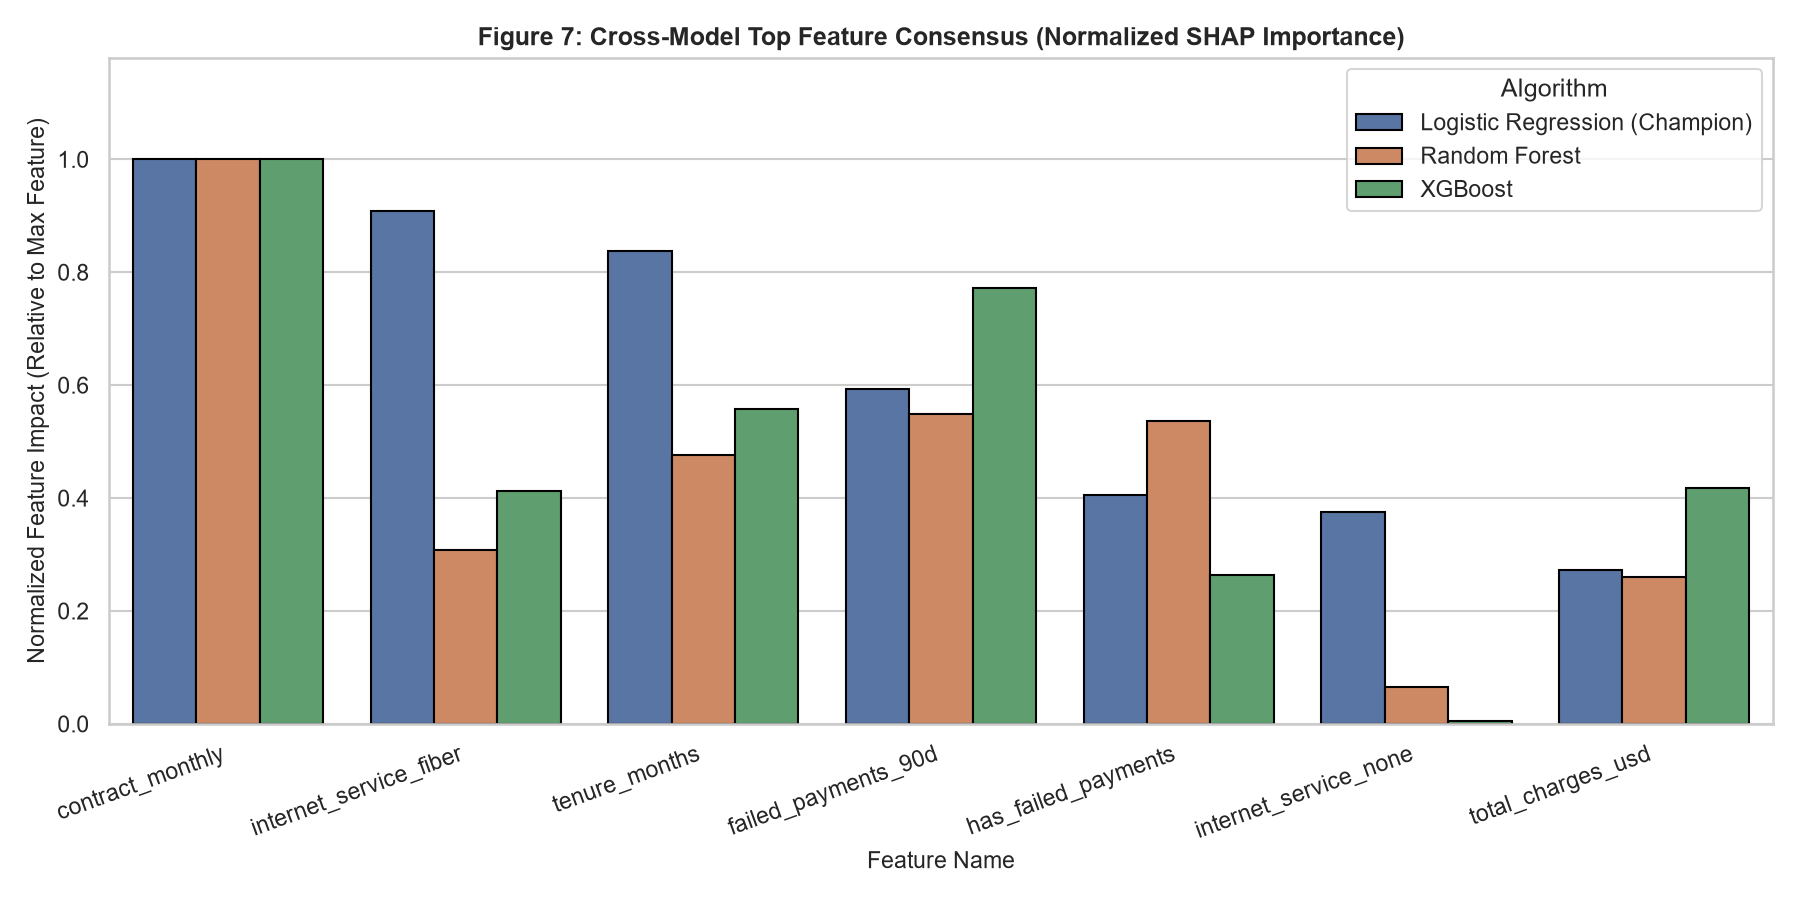

In [6]:
comp_df = pd.read_csv(PROJECT_ROOT / 'outputs' / 'tables' / 'feature_importance_comparison.csv')
display(comp_df.head(8))

p7 = PROJECT_ROOT / 'outputs' / 'shap' / '07_supporting_models_shap_comparison.png'
if p7.exists():
    display(Image(filename=str(p7)))

### 6. Actionable Business Retention Playbook

We translate the model findings into an operational retention strategy for ConnectTel's retention team.

In [7]:
playbook_df = pd.read_csv(PROJECT_ROOT / 'outputs' / 'tables' / 'business_action_playbook.csv')
for i, row in playbook_df.iterrows():
    print(f"Risk Driver {i+1}: {row['Risk_Driver']}")
    print(f"  Target Segment: {row['Target_Customer_Segment']}")
    print(f"  Evidence:       {row['Empirical_Evidence']}")
    print(f"  Intervention:   {row['Actionable_Retention_Intervention']}")
    print(f"  Channel:        {row['Primary_Channel']}")
    print(f"  Success Metric: {row['Success_Metric']}\n")

Risk Driver 1: Month-to-Month Contract
  Target Segment: Monthly subscribers approaching month 6-12
  Evidence:       Odds Ratio: 7.04x | Churn Rate: 32.4% vs ~12% on long-term contracts
  Intervention:   Launch proactive 'Commitment Bonus' campaign offering a 15% discount on a 1-year agreement plus 3 months of complimentary security service.
  Channel:        Email & In-App notification at bill cycle day 20
  Success Metric: Contract migration rate (monthly -> annual)

Risk Driver 2: Failed Payment Delinquency (90d)
  Target Segment: Subscribers with 1 or 2 payment failures in last 90 days
  Evidence:       Odds Ratio: 1.75x per failure | Churn Rate: 8.6% (0 fails) -> 26.9% (2 fails)
  Intervention:   Deploy automated 'Smart Recovery' workflows: frictionless retry links via SMS, payment plan options, and temporary grace period rather than harsh suspension.
  Channel:        SMS payment reminder & Interactive Voice Response (IVR)
  Success Metric: Payment recovery rate without subscrip

### 7. Phase 3 Conclusion

- **Explainability Verified:** SHAP and odds ratios demonstrate complete alignment on `contract_monthly`, `failed_payments_90d`, and `tenure_months` as the dominant churn predictors.
- **Granular Transparency:** Individual customer predictions can now be diagnosed on demand using waterfall decompositions.
- **Actionable Strategy:** ConnectTel's retention team has concrete, prioritized playbooks to intervene before high-risk customers cancel.

**Ready for Next Stages:** Live interactive demonstration app, final locked test set evaluation, and presentation deliverables.